In [1]:
%pip install "pandas>=2.0" numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


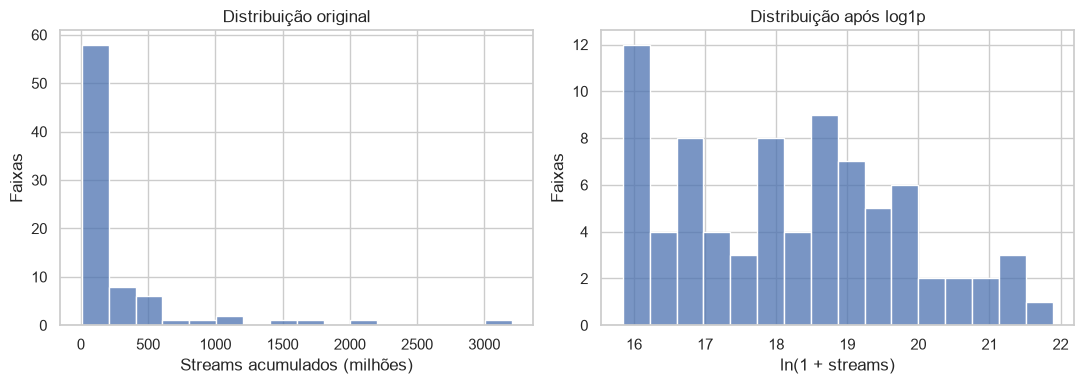

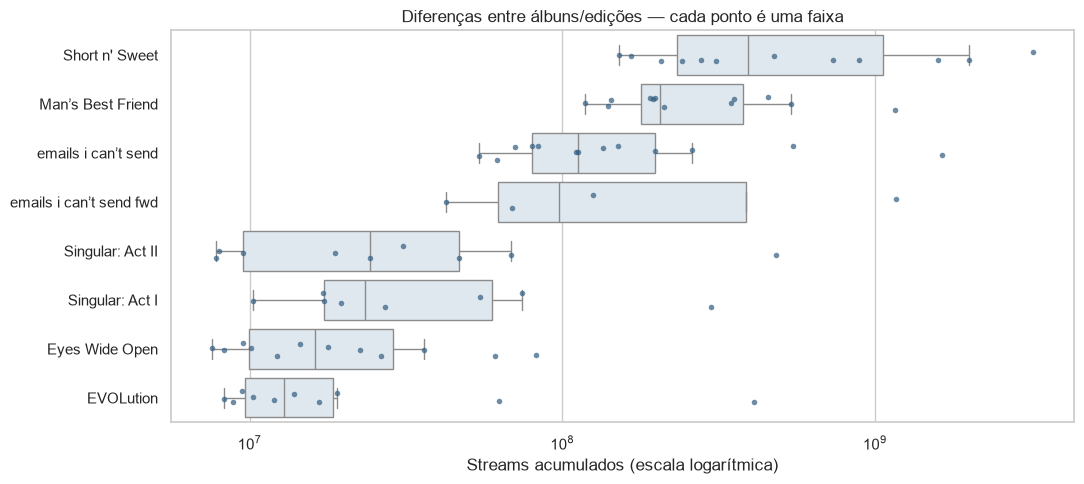

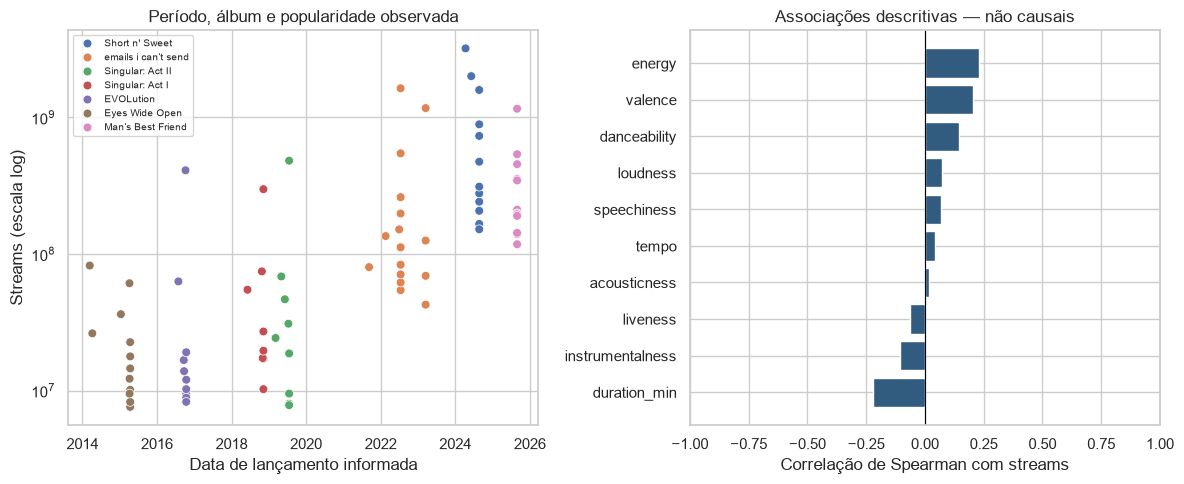

RESUMO POR ÁLBUM
                          n  median_streams  mean_streams min_release max_release
album                                                                            
Short n' Sweet           12     392594344.0  8.540383e+08  2024-04-11  2024-08-23
Man’s Best Friend        12     204800623.0  3.370897e+08  2025-08-29  2025-08-29
emails i can’t send      13     111995791.0  2.691010e+08  2021-09-09  2022-07-15
emails i can’t send fwd   4      97267146.0  3.518013e+08  2023-03-17  2023-03-17
Singular: Act II          9      24259454.0  7.739587e+07  2019-03-08  2019-07-19
Singular: Act I           8      23314015.5  6.484545e+07  2018-06-06  2018-11-09
Eyes Wide Open           12      16149240.0  2.569642e+07  2014-03-14  2015-04-14
EVOLution                10      12927204.0  5.714612e+07  2016-07-29  2016-10-14
CORRELAÇÕES DESCRITIVAS
duration_min       -0.219175
instrumentalness   -0.107225
liveness           -0.062171
acousticness        0.016808
tempo               0.0

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

OUT = Path("results")
OUT.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
df = pd.read_csv("sabrina_original.csv", sep=";")
original = df.copy(deep=True)

for col in ["spotify_streams", "videoclip_views"]:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(".", "", regex=False), errors="raise"
    )
df["instrumentalness"] = pd.to_numeric(
    df["instrumentalness"].astype(str).str.replace(",", ".", regex=False),
    errors="raise"
)
df["release_date"] = pd.to_datetime(
    df["release_date"], format="mixed", dayfirst=True, errors="raise"
)
assert len(df) == len(original)
assert df["spotify_streams"].notna().all()
assert (df["spotify_streams"] >= 0).all()
df["duration_min"] = df["duration_ms"] / 60000
df["log_streams"] = np.log1p(df["spotify_streams"])


df["album_family"] = df["album"].replace({
    "emails i can’t send fwd": "emails i can’t send"
})

summary = df.groupby("album").agg(
    n=("spotify_streams", "size"),
    median_streams=("spotify_streams", "median"),
    mean_streams=("spotify_streams", "mean"),
    min_release=("release_date", "min"),
    max_release=("release_date", "max")
).sort_values("median_streams", ascending=False)
summary.to_csv(OUT / "album_summary.csv")

features = ["duration_min", "acousticness", "danceability", "energy",
            "instrumentalness", "liveness", "loudness", "speechiness",
            "tempo", "valence"]
rho = df[features + ["spotify_streams"]].corr(method="spearman")[
    "spotify_streams"
].drop("spotify_streams").sort_values()
rho.rename("spearman").to_csv(OUT / "spearman_correlation.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["spotify_streams"] / 1e6, bins=16, ax=axes[0])
axes[0].set(xlabel="Streams acumulados (milhões)", ylabel="Faixas",
            title="Distribuição original")
sns.histplot(df["log_streams"], bins=16, ax=axes[1])
axes[1].set(xlabel="ln(1 + streams)", ylabel="Faixas",
            title="Distribuição após log1p")
fig.tight_layout()
fig.savefig(OUT / "streams_distribution.png", dpi=170)
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
order = summary.index.tolist()
sns.boxplot(data=df, x="spotify_streams", y="album", order=order,
            showfliers=False, ax=ax, color="#dce8f2")
sns.stripplot(data=df, x="spotify_streams", y="album", order=order,
              jitter=0.15, alpha=0.7, size=4, ax=ax, color="#315c80")
ax.set_xscale("log")
ax.set(xlabel="Streams acumulados (escala logarítmica)", ylabel="",
       title="Diferenças entre álbuns/edições — cada ponto é uma faixa")
fig.tight_layout()
fig.savefig(OUT / "streams_per_album.png", dpi=170)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(data=df, x="release_date", y="spotify_streams",
                hue="album_family", ax=axes[0], s=40)
axes[0].set_yscale("log")
axes[0].set(xlabel="Data de lançamento informada", ylabel="Streams (escala log)",
            title="Período, álbum e popularidade observada")
axes[0].legend(fontsize=7, title=None)
axes[1].barh(rho.index, rho.values, color="#315c80")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set(xlim=(-1, 1), xlabel="Correlação de Spearman com streams",
            title="Associações descritivas — não causais")
fig.tight_layout()
fig.savefig(OUT / "period_and_associations.png", dpi=170)
plt.show()

df.to_csv(OUT / "exploratory_data.csv", index=False)
print("RESUMO POR ÁLBUM")
print(summary.to_string())
print("CORRELAÇÕES DESCRITIVAS")
print(rho.to_string())
print("Assimetria original:", df["spotify_streams"].skew())
print("Assimetria log1p:", df["log_streams"].skew())
print("Famílias de álbum:", df["album_family"].nunique())
print("Maiores streams:")
print(df.nlargest(5, "spotify_streams")[["track_name", "album", "spotify_streams"]].to_string(index=False))